![Banner](../images/09_06_banner_rs_lidar.png)


# LiDAR Fundamentals

LiDAR (light detection and ranging) measures distance by timing laser pulses and turns millions of those measurements into a three-dimensional point cloud. Because a pulse can pass through gaps in a canopy, one flight records the treetops, the structure inside the crowns and the ground underneath, which no passive image can do. This notebook explains how LiDAR works, how the data are acquired and delivered, what the data are used for, and then reads, inspects and writes real point clouds with `geolattice.rsense.lidar`.

Eight notebooks take a point cloud from the instrument to a map.

- **LiDAR Fundamentals.** This notebook. How ranging, GNSS and the IMU make a point, how the data are delivered, and reading, inspecting and writing clouds with `geolattice.rsense.lidar`.
- **LiDAR Processing: Quality Control, Cleaning, Ground Classification and Surface Models.** Check coverage, remove noise, classify ground, and build a DEM, DSM and canopy height model on a Mississippi forest and the University at Buffalo campus.
- **Terrain and Hydrology from LiDAR DEMs.** A 1 m DEM of Six Mile Creek in Ithaca, with slope, landforms, streams, wetness and flood extent.
- **Forest Structure and Individual Trees from LiDAR.** Area-based canopy metrics and individual trees at Madison, Mississippi, compared with a denser Ithaca survey.
- **Buildings and Urban Features from LiDAR.** Separate roofs from trees, outline footprints, measure roof shape and estimate sunlight at Autzen Stadium and the University at Buffalo.
- **Point Cloud Classification with Machine Learning and Deep Learning.** Random forest, gradient boosting, PointNet and PointNet++ on the Autzen survey, trained and tested on separate areas.
- **Spaceborne LiDAR: GEDI and ICESat-2.** GEDI and ICESat-2, quality-filtered and compared with airborne LiDAR over Madison, Mississippi.
- **Large-Area LiDAR Processing: Tiling, Streaming, Parallel Work and the GPU.** Ten USGS 3DEP tiles around Ithaca (135 million points): a tile index, streaming, parallel mosaics and terrain on the GPU.


## Overview

LiDAR is an **active** remote sensing technique: the instrument supplies its own light, a short pulse of laser energy, and records the echo. The time the pulse takes to travel to a surface and back gives the distance to that surface. Combined with the exact position and orientation of the instrument at the moment of firing, each echo becomes a point with x, y and z coordinates. A modern airborne survey collects hundreds of thousands to a few million such points every second.

A short history:

- **1960 to 1970s.** The laser was demonstrated in 1960. Within a few years it was used to range the Moon (retroreflectors left by Apollo 11 in 1969) and, in the 1970s, NASA flew airborne laser profilers that measured a single line of heights beneath the aircraft.
- **1990s.** The Global Positioning System (GPS) and accurate inertial measurement units (IMUs) made it possible to know where an aircraft was, and how it was tilted, to a few centimetres and a few thousandths of a degree. Scanning mirrors spread the pulses across a swath, and commercial airborne laser scanning (ALS) was born.
- **2000s.** Full-waveform digitisers recorded the whole returned signal instead of a few discrete echoes. Terrestrial laser scanners (TLS) on tripods and mobile laser scanners (MLS) on vehicles spread to surveying, engineering and forestry. NASA's ICESat (2003 to 2009) carried the first spaceborne laser altimeter for Earth's ice and land.
- **2010s.** National programs began mapping whole countries: the USGS 3D Elevation Program (3DEP), the Netherlands' AHN, England's Environment Agency survey, Denmark, Spain and many more. Geiger-mode and single-photon systems, which detect individual photons, raised collection rates. ICESat-2 (2018) and GEDI on the International Space Station (2018, science data from 2019) began sampling forests and terrain worldwide.
- **2020s.** Small, cheap sensors on drones (UAV LiDAR) and in phones, and automotive LiDAR for self-driving vehicles, made point clouds a routine data type. Cloud-optimised formats (COPC, EPT) let users stream only the part of a national archive they need.


### How LiDAR works

**Ranging.** A pulse leaves the laser at time $t_0$, reflects from a surface and returns at $t_1$. Light travels at $c \approx 299{,}792{,}458$ m/s, and the pulse covers the distance twice, so the range is

$$R = \frac{c\,(t_1 - t_0)}{2} = \frac{c\,\Delta t}{2}.$$

A target 1,000 m away returns its echo after about 6.7 microseconds. A timing error of 1 nanosecond moves the range by 15 cm, so LiDAR receivers time echoes to a few tens of picoseconds.

**Georeferencing.** The range alone is a distance along the laser beam. The system turns it into a ground coordinate with three more measurements made at the same instant:

1. **GNSS** (GPS and other satellite navigation systems) gives the position of the sensor, usually corrected against a base station on the ground or a precise orbit service.
2. **The IMU** gives the attitude of the sensor: roll, pitch and heading.
3. **The scanner** reports the angle at which the beam left the instrument.

The point is then $\mathbf{p} = \mathbf{p}_{\text{GNSS}} + \mathbf{R}_{\text{IMU}}\,(\mathbf{l} + \mathbf{R}_{\text{bore}}\,\mathbf{r}_{\text{scan}}\,R)$, where $\mathbf{l}$ is the lever arm between the GNSS antenna and the laser, $\mathbf{R}_{\text{bore}}$ is the small boresight rotation between IMU and laser, and $\mathbf{r}_{\text{scan}}$ is the unit vector of the beam. Errors in any of these terms (GNSS position, IMU angle, boresight calibration, range) all end up in the point. An angular error of 0.005 degrees at 1,000 m range moves a point by about 9 cm, which is why calibration matters.

**Wavelength.** Most topographic systems use near-infrared light at **1064 nm** (Nd:YAG lasers) or **1550 nm** (fibre lasers, safer for eyes at higher power). Vegetation reflects strongly at these wavelengths, while water absorbs them, so lakes appear as holes in the data. **Bathymetric** LiDAR adds a green **532 nm** channel that penetrates clear water and maps the bottom. Automotive and many drone sensors use **905 nm** diodes.

**Footprint.** The beam spreads slightly as it travels. With a divergence of $\gamma$ radians the footprint diameter at range $R$ is roughly $D \approx \gamma R$: 0.25 mrad at 1,000 m gives a 25 cm spot. GEDI's footprint on the ground is about 25 m wide, ICESat-2's about 11 to 17 m.

**Multiple returns.** A footprint can be partly intercepted by leaves and partly continue to the ground. Each surface that reflects enough energy produces a separate echo, so one pulse can give several **returns**: the first return is usually the top of the canopy or a roof, intermediate returns come from branches and understory, and the last return is often the ground. Every point records its `return_number` and the `number_of_returns` of its pulse.

**Discrete return versus full waveform.** Discrete-return systems detect peaks in the returned signal in real time and keep up to 4 to 15 of them. Full-waveform systems digitise the whole returned energy as a function of time (every nanosecond or so), so the user can extract more returns later and measure the shape of each echo. GEDI is a full-waveform instrument; its products are summaries of the waveform.

**Single-photon and Geiger-mode LiDAR.** Instead of measuring a strong echo, these detectors are sensitive enough to register single photons. They fire many weak pulses at high rates (tens of kilohertz to megahertz) and build up the surface from photon statistics. ICESat-2's ATLAS instrument works this way.

**Intensity.** Each return also records the strength of the echo. Intensity depends on the reflectance of the target at the laser wavelength, the range, the angle of incidence and the fraction of the footprint the target filled. It looks like a near-infrared photograph and helps separate asphalt from grass or paint lines from road, but it is rarely calibrated, so values are not comparable between surveys.

**Point density and spacing.** Density (points per m²) controls the smallest detail the data can resolve. For one flight line it is approximately

$$\rho \approx \frac{\text{PRF}}{v \cdot W}, \qquad W = 2H\tan(\theta/2),$$

where PRF is the pulse repetition frequency, $v$ the ground speed, $W$ the swath width, $H$ the flying height and $\theta$ the full scan angle. Overlap between flight lines and multiple returns raise the density further. The nominal point spacing is $1/\sqrt{\rho}$.


### How LiDAR data are acquired

**Platforms.**

| Platform | Typical height or range | Typical density | Typical use |
|---|---|---|---|
| Airborne, fixed wing (ALS) | 500 to 4,000 m above ground | 2 to 50 points/m² | Regional and national terrain, forestry, floodplains |
| Airborne, helicopter | 100 to 500 m | 20 to 200 points/m² | Power lines, railways, corridors |
| Drone (UAV LiDAR) | 30 to 120 m | 100 to 1,000+ points/m² | Small sites, forestry plots, construction, mines |
| Terrestrial (TLS) on a tripod | 1 to 1,000 m range | millimetres between points | Forest plots, buildings, cliffs, heritage |
| Mobile (MLS) on a car, train, boat or backpack | 1 to 300 m range | very high along the route | Roads, rail, street furniture, city models |
| Bathymetric airborne | 300 to 600 m | 1 to 20 points/m² | Shallow seas, rivers, coastlines |
| Spaceborne (ICESat-2, GEDI) | about 400 to 500 km | sparse footprints or photon tracks | Global canopy height, ice sheets, sea ice |

**Scanning mechanisms.** An oscillating mirror sweeps the beam from side to side and leaves a zigzag pattern on the ground; a rotating polygon mirror gives parallel lines; a nutating (Palmer) scanner draws ellipses, so each spot is seen from two directions; Risley prisms in small drone sensors produce rosette patterns.

**An airborne survey, step by step.**

1. **Flight planning.** The surveyor chooses flying height, speed, scan angle and pulse rate to reach the required density, and spaces the flight lines so neighbouring swaths overlap (often 20 to 50 %). Calm weather, leaf-off season for terrain mapping or leaf-on for forest structure, and no snow or flooding are chosen where possible.
2. **Ground control.** GNSS base stations log positions during the flight, and surveyed check points are placed on open, flat ground for later accuracy testing.
3. **Collection.** The aircraft flies the lines while the laser, GNSS and IMU log their data, often together with a camera.
4. **Trajectory processing.** GNSS and IMU data are combined in a Kalman filter to give the sensor's position and attitude for every pulse.
5. **Point generation and calibration.** Ranges, scan angles and the trajectory are combined into points. Overlapping flight lines are compared, and boresight and timing offsets are adjusted (strip adjustment) until the lines agree.
6. **Classification.** Software and human editors label points as ground, vegetation, buildings, water, noise and so on.
7. **Quality control and delivery.** The vertical accuracy is tested against the check points, and the producer delivers tiled point clouds, a digital elevation model (DEM), breaklines around water, intensity images and metadata.

**Accuracy.** Modern ALS reaches a vertical root mean square error (RMSEz) of about 5 to 10 cm on open hard surfaces. The USGS 3DEP Lidar Base Specification defines **quality levels**:

| Quality level | Aggregate nominal pulse density | Non-vegetated vertical accuracy (RMSEz) |
|---|---|---|
| QL0 | ≥ 8 points/m² | ≤ 5 cm |
| QL1 | ≥ 8 points/m² | ≤ 10 cm |
| QL2 | ≥ 2 points/m² | ≤ 10 cm |
| QL3 | ≥ 0.5 points/m² | ≤ 20 cm |


### Data products and file formats

**LAS** is the binary exchange format of the American Society for Photogrammetry and Remote Sensing (ASPRS). A LAS file has a public header (version, point format, number of points, scale and offset, bounds), variable length records (the coordinate reference system and other metadata) and the point records. Coordinates are stored as integers and recovered as $X = X_{\text{int}} \cdot \text{scale} + \text{offset}$, so a scale of 0.001 means millimetre precision.

| LAS version | Year | Main additions |
|---|---|---|
| 1.0 | 2003 | Point formats 0 and 1 (GPS time) |
| 1.1 | 2005 | File source ID, user data |
| 1.2 | 2008 | Point formats 2 and 3 (RGB colour) |
| 1.3 | 2010 | Point formats 4 and 5 (waveform packets) |
| 1.4 | 2011 to 2019 | Point formats 6 to 10: 15 returns, 256 classes, WKT coordinate systems, NIR channel |

Related formats:

| Format | What it is |
|---|---|
| **LAZ** | Lossless compression of LAS (LASzip), typically 5 to 10 times smaller |
| **COPC** | Cloud-Optimized Point Cloud: one LAZ file whose points are arranged in an octree, so a program can read just a region or a coarse level of detail with HTTP range requests |
| **EPT** | Entwine Point Tiles: a folder of octree tiles plus a JSON description; the USGS 3DEP archive on Amazon Web Services is published this way |
| **E57** | ASTM exchange format for terrestrial scanners, with images and scan positions |
| **PLY, PCD, XYZ** | Simple formats used by CloudCompare, MeshLab, Open3D and the Point Cloud Library |
| **LASX** | An index file written by ArcGIS next to a LAS file to speed up display; it holds no points |

**Classification codes.** ASPRS defines standard classes for LAS 1.4 (point formats 6 to 10):

| Code | Class | Code | Class |
|---|---|---|---|
| 0 | Created, never classified | 10 | Rail |
| 1 | Unclassified | 11 | Road surface |
| 2 | Ground | 12 | Reserved (used for overlap points in older LAS versions) |
| 3 | Low vegetation | 13 | Wire guard (shield) |
| 4 | Medium vegetation | 14 | Wire conductor (phase) |
| 5 | High vegetation | 15 | Transmission tower |
| 6 | Building | 16 | Wire-structure connector |
| 7 | Low point (noise) | 17 | Bridge deck |
| 8 | Reserved (model key point in older versions) | 18 | High noise |
| 9 | Water | 64 to 255 | User definable |

**Derived rasters.** A **DEM** or DTM (digital terrain model) is the bare-earth surface from ground points. A **DSM** (digital surface model) is the highest surface, including trees and roofs. The **CHM** (canopy height model) or nDSM is DSM minus DEM: the height of objects above the ground. Intensity images, point-density grids and hillshades are common quality-control rasters.


### Applications

- **Terrain and water.** Bare-earth DEMs for flood modelling and floodplain maps, drainage and culvert mapping, coastal erosion, sea-level-rise exposure, and the hydrologically conditioned elevation data behind national hydrography.
- **Forestry and ecology.** Canopy height, cover, vertical structure and gaps; tree counts and crown sizes; timber volume and aboveground biomass for carbon accounting; habitat models for birds and mammals that depend on canopy layering.
- **Urban areas and infrastructure.** Building footprints, heights and roof shapes for 3D city models and solar potential; power-line clearance and vegetation encroachment; road and railway corridor surveys; bridge and dam monitoring; telecommunication line-of-sight planning.
- **Geology and hazards.** Fault scarps, landslides and debris flows, volcanic deformation and post-event change detection by differencing surveys from different dates.
- **Archaeology and cultural heritage.** Removing vegetation digitally reveals buried walls, roads and field systems, for example the Maya settlements under the Guatemalan rainforest and the medieval cities around Angkor in Cambodia. TLS documents monuments in millimetre detail.
- **Cryosphere.** Ice-sheet and glacier elevation change and sea-ice freeboard from ICESat and ICESat-2.
- **Agriculture.** Field drainage design, land levelling, erosion and orchard canopy structure.
- **Transport and robotics.** LiDAR on cars, robots and drones for navigation, obstacle detection and high-definition maps.
- **Global carbon.** GEDI's canopy-height and biomass products and ICESat-2's canopy heights give the first near-global samples of forest structure.


### Accessibility

| Source | Coverage and notes |
|---|---|
| **USGS 3DEP** (The National Map, apps.nationalmap.gov) | Most of the United States; point clouds and 1 m and 1/3 arc-second DEMs; free |
| **USGS 3DEP on AWS** (`s3://usgs-lidar-public`) | The same point clouds as EPT, readable with PDAL; free |
| **Microsoft Planetary Computer** | `3dep-lidar-copc` (COPC tiles) and derived 3DEP rasters through STAC |
| **OpenTopography** (opentopography.org) | Curated high-resolution topography worldwide, with on-demand processing |
| **NOAA Digital Coast** | Coastal topographic and bathymetric LiDAR for the United States |
| **State and provincial programs** | For example the NYS GIS Clearinghouse for New York, the source of LiDAR tiles like the ones used here |
| **National programs elsewhere** | Netherlands (AHN), England (Environment Agency), Denmark, Finland, Spain (PNOA), Switzerland, New Zealand and others publish national point clouds |
| **NASA Earthdata** (search.earthdata.nasa.gov) | GEDI L1B to L4 and ICESat-2 ATL03, ATL06 and ATL08 granules; free login required |

**Python tools:**

- `laspy` reads and writes LAS, LAZ (with the `lazrs` backend) and COPC.
- `PDAL` runs processing pipelines and reads EPT and many other formats.
- `h5py` reads GEDI and ICESat-2 HDF5 files.
- `pyproj`, `rasterio`, `rioxarray` and `geopandas` handle coordinate systems, rasters and vectors.
- `geolattice.rsense.lidar` wraps all of these in one `PointCloud` container with readers, filters, ground classification, surfaces, terrain, forest, urban and spaceborne tools.


## Working with LiDAR Data in GeoLattice

The rest of this notebook turns the concepts above into numbers and pictures with real data: it plans a flight, simulates a full waveform from real returns, reads LiDAR files of different ages and formats, fixes their units and coordinate reference systems, and explores what the points contain.


### Learning objectives

1. Compute ranges, footprints, swath widths and point densities from the LiDAR equations.
2. Explain multiple returns and the difference between discrete-return and full-waveform data.
3. Read LAS headers and know the LAS versions, point formats, LAZ, COPC and LASX files.
4. Read point clouds with `geolattice.rsense.lidar.read_las` and fix units and coordinate reference systems (feet, degrees, compound vertical datums).
5. Summarise classes, returns, density and intensity, and draw cross-sections and 3D views.
6. Read only a window or a coarse level of detail from a COPC file.
7. Write LAZ and PLY files and find public LiDAR for an area.


### Data

All files are in the `data/` folder next to this notebook.

| File | Content |
|---|---|
| `madison.copc.laz` | Airborne LiDAR, Madison, Mississippi: 4.07 million classified points, COPC, LAS 1.4, NAD83 Mississippi West state plane in US survey feet |
| `madison_utm.laz` | The same cloud reprojected to UTM zone 15N in metres (written by this notebook) |
| `UB/*.las`, `UB/*.laz`, `UB/*.lasx` | Airborne LiDAR of the University at Buffalo North Campus, New York, flown on 17 April 2008: five tiles of about 2.5 million points, LAS 1.0, geographic NAD83 coordinates; each tile as LAS, as LAZ and with an ArcGIS LASX index |
| `Ithaca/*.las` | USGS 3DEP NY Finger Lakes 2020 tiles around Ithaca, New York: ten 1.5 km tiles of 12 to 15 million points, LAS 1.4, UTM zone 18N with NAVD88 heights |
| `autzen_window.laz` | A 440 m window of the Autzen Stadium survey, Eugene, Oregon, with buildings classified (used in later notebooks) |


### Contents

1. Setup
2. The LiDAR equations in numbers
3. Multiple returns and a simulated full waveform
4. File formats: headers, LAS versions, LAZ and LASX
5. Classification codes
6. Reading a point cloud and fixing units
7. Coordinate reference systems in three datasets
8. Exploring classes, returns, density and intensity
9. Cross-sections and 3D views
10. Cloud-native access: reading a window from COPC
11. Writing point clouds and finding public LiDAR
12. Summary and exercises

The following notebooks in this chapter build on this one:

- [LiDAR processing: quality control, cleaning, ground classification and surface models](09_06_02_lidar_processing_quality_control_cleaning_ground_classification_and_surface_models.ipynb)
- [Terrain and hydrology from LiDAR DEMs](09_06_03_terrain_and_hydrology_from_lidar_dems.ipynb)
- [Forest structure and individual trees](09_06_04_forest_structure_and_individual_trees_from_lidar.ipynb)
- [Buildings and urban features](09_06_05_buildings_and_urban_features_from_lidar.ipynb)
- [Point cloud classification with machine learning and deep learning](09_06_06_point_cloud_classification_with_machine_learning_and_deep_learning.ipynb)
- [Spaceborne LiDAR: GEDI and ICESat-2](09_06_07_spaceborne_lidar_gedi_and_icesat_2.ipynb)
- [Large-area processing: tiling, streaming and the GPU](09_06_08_large_area_lidar_processing_tiling_streaming_parallel_work_and_the_gpu.ipynb)


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings (e.g. LAZ backend notices)

import os  # file sizes
import time  # timing
import numpy as np  # arrays
import pandas as pd  # tables
import rasterio  # raster I/O (used by the plotting helpers)
import matplotlib.pyplot as plt  # figures
from pyproj import CRS, Transformer  # coordinate reference systems

import geolattice.rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.core import ASPRS_CLASSES  # ASPRS class code -> name

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages for the whole session
plt.rcParams.update({"figure.dpi": 110})  # figure resolution
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))  # version and array backend

geolattice.rsense 0.3.49 | backend: cpu


In [2]:
from pathlib import Path  # file paths

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_06_lidar/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_06_lidar"), Path("../../../../Data/08_remote_sensing/08_06_lidar"))
             if p.is_dir()), None)
if DATA is None:  # neither location exists
    # stop with a clear message
    raise FileNotFoundError("Run the notebook from its own folder or from the GeoLattice repository root.")
OUT = DATA.parent / "outputs"  # folder for the products this notebook writes
OUT.mkdir(exist_ok=True)  # create it if needed

MADISON = DATA / "madison.copc.laz"  # classified ALS, Mississippi, US survey feet
UB = sorted((DATA / "UB").glob("*.laz"))  # University at Buffalo 2008 tiles (LAZ copies)
ITHACA = sorted((DATA / "Ithaca").glob("*.las"))  # USGS 3DEP 2020 tiles around Ithaca
print(f"{MADISON.name} | {len(UB)} UB tiles | {len(ITHACA)} Ithaca tiles")  # what was found

madison.copc.laz | 5 UB tiles | 10 Ithaca tiles


## The LiDAR equations in numbers

The table applies the ranging and footprint equations for an airborne sensor at three flying heights: the round-trip time of a pulse, the footprint for a typical 0.25 mrad beam divergence, and the range error caused by a 1 ns timing error.


In [3]:
C = 299_792_458  # speed of light (m/s)
rows = []  # one row per flying height
for H in (500, 1000, 2000, 4000):  # flying heights above ground (m)
    rows.append({"flying height (m)": H,  # the height
                 "round trip (µs)": round(2 * H / C * 1e6, 2),  # Δt = 2R / c
                 "footprint at 0.25 mrad (cm)": round(0.25e-3 * H * 100, 1),  # D ≈ γ R
                 "range error for 1 ns (cm)": round(C * 1e-9 / 2 * 100, 1)})  # ΔR = c Δt / 2
pd.DataFrame(rows)  # show the table

,flying height (m),round trip (µs),footprint at 0.25 mrad (cm),range error for 1 ns (cm)
0,500,3.34,12.5,15.0
1,1000,6.67,25.0,15.0
2,2000,13.34,50.0,15.0
3,4000,26.69,100.0,15.0


**Flight planning.** The next cell writes the density equation as a function and plans a survey. For each flying height it gives the swath width, the spacing between flight lines for 30 % side overlap, the single-pass pulse density and the density once the overlap is counted. The figure shows how density falls with flying height and rises with pulse rate; the dashed lines mark the 3DEP QL2 (2 points/m²) and QL1 (8 points/m²) thresholds.


,swath (m),line spacing (m),"pulses/m², one line","pulses/m², with overlap"
flying height (m),,,,
500,363.97,254.78,15.26,21.80
1000,727.94,509.56,7.63,10.90
1500,1091.91,764.34,5.09,7.27
2000,1455.88,1019.12,3.82,5.45
3000,2183.82,1528.67,2.54,3.63


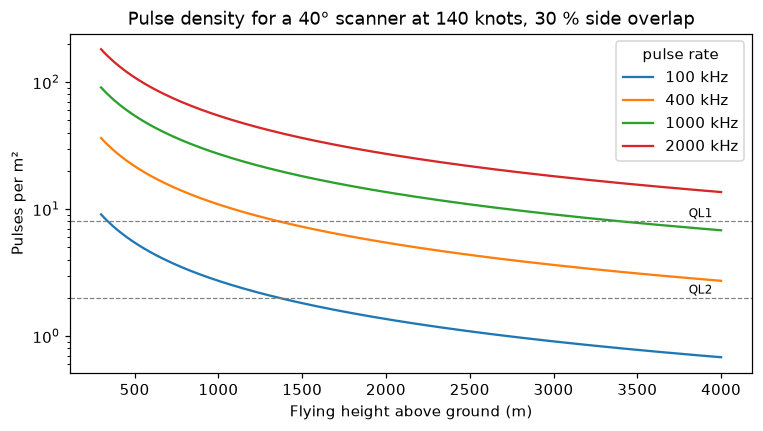

In [4]:
def flight_plan(H, prf_khz=400, speed_kn=140, fov_deg=40, overlap=0.3):  # density of an ALS survey
    W = 2 * H * np.tan(np.radians(fov_deg) / 2)  # swath width (m)
    v = speed_kn * 0.5144  # ground speed in m/s (1 knot = 0.5144 m/s)
    rho1 = prf_khz * 1e3 / (v * W)  # pulses per m² from one flight line
    return {"swath (m)": W, "line spacing (m)": W * (1 - overlap),  # swath and line spacing
            "pulses/m², one line": rho1, "pulses/m², with overlap": rho1 / (1 - overlap)}  # densities

plan = pd.DataFrame({H: flight_plan(H) for H in (500, 1000, 1500, 2000, 3000)}).T.round(2)  # five heights
plan.index.name = "flying height (m)"  # label the index
display(plan)  # show the plan

fig, ax = plt.subplots(figsize=(8, 4))  # one panel
Hs = np.linspace(300, 4000, 200)  # flying heights to plot
for prf in (100, 400, 1000, 2000):  # pulse rates (kHz)
    ax.plot(Hs, [flight_plan(h, prf_khz=prf)["pulses/m², with overlap"] for h in Hs], label=f"{prf} kHz")  # density curve
for q, d in (("QL2", 2), ("QL1", 8)):  # 3DEP thresholds
    ax.axhline(d, ls="--", c="grey", lw=0.8); ax.text(3950, d * 1.08, q, ha="right", fontsize=8)  # dashed line and label
ax.set(xlabel="Flying height above ground (m)", ylabel="Pulses per m²", yscale="log",  # axes
       title="Pulse density for a 40° scanner at 140 knots, 30 % side overlap")  # title
ax.legend(title="pulse rate"); plt.show()  # legend and draw

## Multiple returns and a simulated full waveform

A pulse that enters a canopy can return several echoes. The cell below takes the real Madison point cloud (read properly in the *Reading a point cloud and fixing units* section), picks the 10 m cell with the most canopy returns that still has ground returns, and treats all returns in a 10 m wide circle there as a single footprint. Summing a Gaussian pulse at the height of every return gives an approximate **waveform**: the returned energy as a function of height. A discrete-return system keeps only the peaks; a full-waveform system keeps the whole curve. The relative heights RH50 and RH98, which GEDI reports, are the heights below which 50 % and 98 % of the energy lies.


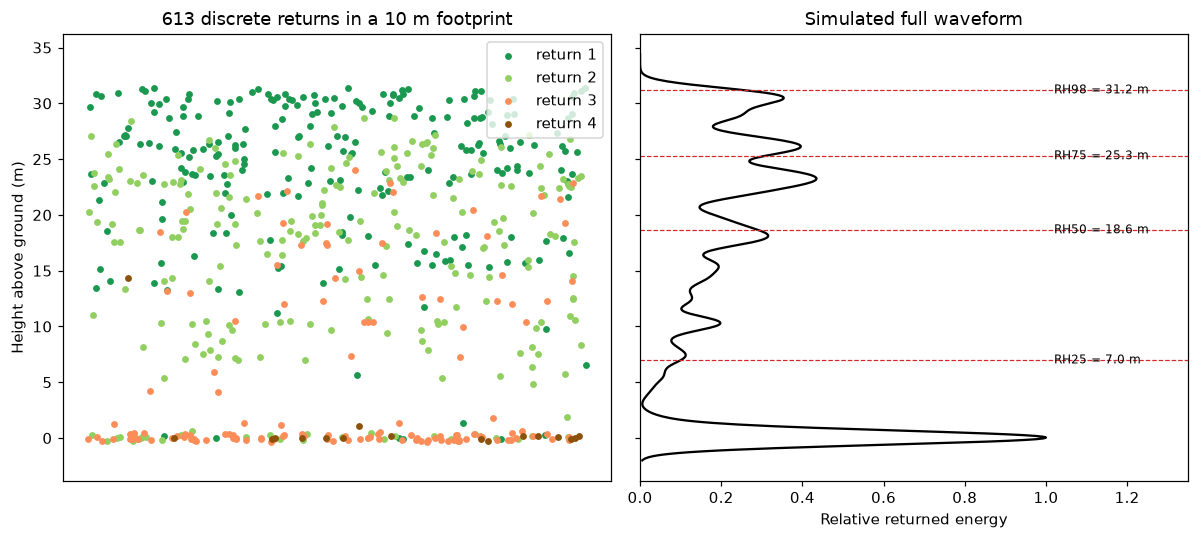

In [5]:
pc_ft = rs.lidar.read_las(MADISON)  # the whole Madison cloud (feet, state plane)
z_m = np.asarray(pc_ft.z) * 0.3048006096  # heights converted from US survey feet to metres
r_ft = 5.0 / 0.3048006096  # a 5 m radius (10 m wide) footprint, in feet
cell = pd.DataFrame({"i": (pc_ft.x // (2 * r_ft)).astype(int), "j": (pc_ft.y // (2 * r_ft)).astype(int),  # 10 m cells
                     "z": z_m, "c": pc_ft["classification"]})  # height and class of every point
cell = cell[cell.c != 7]  # drop noise points
cell["h"] = cell.z - cell.groupby(["i", "j"]).z.transform("min")  # height above the lowest point in the cell
stats = cell.groupby(["i", "j"]).agg(ground=("c", lambda c: (c == 2).sum()),  # ground returns per cell
                                     canopy=("h", lambda h: (h > 5).sum()))  # returns more than 5 m up
best = stats[stats.ground >= 5].canopy.idxmax()  # the cell with most canopy returns that still sees the ground
cx, cy = (best[0] + 0.5) * 2 * r_ft, (best[1] + 0.5) * 2 * r_ft  # centre of that cell (feet)
inside = ((pc_ft.x - cx) ** 2 + (pc_ft.y - cy) ** 2 < r_ft ** 2) & (pc_ft["classification"] != 7)  # returns in the footprint
zf = z_m[inside]  # their heights (m)
ground_z = zf[pc_ft["classification"][inside] == 2].mean()  # mean ground height in the footprint
h = zf - ground_z  # height above ground of every return

zz = np.linspace(-2, h.max() + 3, 500)  # heights at which to evaluate the waveform
sigma = 0.6  # width of the outgoing pulse expressed in metres of height
wave = np.exp(-0.5 * ((zz[:, None] - h[None, :]) / sigma) ** 2).sum(1)  # sum of one Gaussian per return
cum = np.cumsum(wave) / wave.sum()  # cumulative energy from the ground up
rh = {p: zz[np.searchsorted(cum, p / 100)] for p in (25, 50, 75, 98)}  # relative heights RH25 to RH98

fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharey=True)  # two panels
rn = pc_ft["return_number"][inside]  # return number of each echo
for k, col in zip(range(1, 5), ("#1a9850", "#91cf60", "#fc8d59", "#8c510a")):  # returns 1 to 4
    m = rn == k  # echoes with this return number
    ax[0].scatter(np.random.default_rng(k).uniform(0, 1, m.sum()), h[m], s=12, color=col, label=f"return {k}")  # jittered
ax[0].set(xticks=[], ylabel="Height above ground (m)", title=f"{inside.sum()} discrete returns in a 10 m footprint")  # axes
ax[0].legend()  # legend
ax[1].plot(wave / wave.max(), zz, c="k")  # the waveform
for p, v in rh.items():  # relative heights
    ax[1].axhline(v, ls="--", lw=0.8, c="C3"); ax[1].text(1.02, v, f"RH{p} = {v:.1f} m", va="center", fontsize=8)  # mark
ax[1].set(xlabel="Relative returned energy", xlim=(0, 1.35), title="Simulated full waveform")  # axes
plt.tight_layout(); plt.show()  # draw

The first returns (green) sit in the upper canopy, later returns lie lower down and the last ones reach the ground, which forms the strong peak at 0 m. The waveform's energy is spread through the canopy; RH98 is close to the top of the tallest crown and RH50 shows where the middle of the energy lies. A real waveform also depends on the reflectance of leaves and ground and on the shape of the outgoing pulse, so this is an illustration, not an instrument simulation.


## File formats: headers, LAS versions, LAZ and LASX

`rs.lidar.las_info` reads only the header and the coordinate reference system of a file, not the points, so it is fast even for very large files. The table compares one file from each dataset.


In [6]:
files = {"Madison (COPC)": MADISON, "UB 2008 (LAS)": DATA / "UB" / "20080417_10901090_ld_p28.las",  # one file each
         "UB 2008 (LAZ)": DATA / "UB" / "20080417_10901090_ld_p28.laz", "Ithaca 2020 (LAS)": ITHACA[0]}
info = {k: rs.lidar.las_info(p) for k, p in files.items()}  # header summaries
keys = ["version", "point_format", "point_count", "scales", "compressed", "generating_software", "creation_date"]  # fields
hdr = pd.DataFrame({k: {f: v.get(f) for f in keys} for k, v in info.items()})  # one column per file
hdr.loc["size (MB)"] = [round(os.path.getsize(p) / 1e6, 1) for p in files.values()]  # file sizes
hdr.loc["CRS"] = [CRS.from_user_input(v["crs"]).name for v in info.values()]  # coordinate reference systems
hdr  # show the table

,Madison (COPC),UB 2008 (LAS),UB 2008 (LAZ),Ithaca 2020 (LAS)
version,1.4,1.0,1.0,1.4
point_format,6,1,1,6
point_count,4068294,2599988,2599988,14748208
scales,"[0.01, 0.01, 0.01]","[1e-07, 1e-07, 0.001]","[1e-07, 1e-07, 0.001]","[0.001, 0.001, 0.001]"
compressed,True,False,True,False
generating_software,PDAL 2.9.3 (756cda),TerraScan,TerraScan,GeoCue LAS Updater
creation_date,2026-01-11,None,None,2020-09-10
size (MB),23.2,72.8,8.1,531.0
CRS,NAD83 / Mississippi West (ftUS),NAD83,NAD83,NAD83(2011) / UTM zone 18N + NAVD88 height - G...


The table shows several things worth knowing:

- The 2008 UB tile is **LAS 1.0, point format 1** (x, y, z, intensity, returns, scan angle, GPS time). Its coordinates are **longitude and latitude**, stored with a scale of 10⁻⁷ degrees (about 1 cm). The 2020 Ithaca and the Madison files are **LAS 1.4, point format 6**, the current standard.
- The same UB tile is about 73 MB as LAS and about 8 MB as LAZ: compression saves close to 90 % with no loss.
- The Ithaca header carries a **compound** coordinate reference system: UTM zone 18N horizontally and NAVD88 heights (geoid model GEOID12B) vertically.

Each UB tile also has a `.lasx` file. It is a spatial index that ArcGIS writes the first time it displays a LAS file; it holds no points and can be deleted or ignored outside ArcGIS.


In [7]:
ub_files = pd.DataFrame([{"tile": p.stem,  # tile name
                          "LAS (MB)": os.path.getsize(p.with_suffix(".las")) / 1e6,  # uncompressed size
                          "LAZ (MB)": os.path.getsize(p) / 1e6,  # compressed size
                          "LASX index (kB)": os.path.getsize(p.with_suffix(".lasx")) / 1e3,  # ArcGIS index size
                          "points": rs.lidar.las_info(p)["point_count"]} for p in UB]).set_index("tile")  # one row per tile
ub_files["compression ratio"] = ub_files["LAS (MB)"] / ub_files["LAZ (MB)"]  # LAS size / LAZ size
ub_files.round(1)  # show the table

,LAS (MB),LAZ (MB),LASX index (kB),points,compression ratio
tile,,,,,
20080417_10851095_ld_p28,68.8,8.7,27.1,2458062,7.9
20080417_10901090_ld_p28,72.8,8.1,27.1,2599988,9.0
20080417_10901095_ld_p28,72.0,9.1,27.6,2572083,7.9
20080417_10951090_ld_p28,69.7,7.6,26.6,2488234,9.2
20080417_10951095_ld_p28,71.0,9.6,27.6,2536230,7.4


## Classification codes

`ASPRS_CLASSES` in `geolattice.rsense.core` maps the class codes to names. The cell counts the codes present in each dataset. Producers do not always follow the table: the 2008 UB tiles use code **12** for overlap points (a convention of older LAS versions), and Madison uses code **11** in a way the next sections examine.


In [8]:
def class_counts(path, n=3_000_000):  # class histogram from the first n points of a file
    import laspy  # LAS reader
    with laspy.open(path) as r:  # open without reading everything
        c = np.asarray(r.read_points(min(n, r.header.point_count)).classification)  # class codes
    return pd.Series(c).value_counts(normalize=True)  # share of each code

codes = pd.DataFrame({"Madison": class_counts(MADISON), "UB 2008": class_counts(UB[1]),  # one column per dataset
                      "Ithaca 2020": class_counts(ITHACA[0])}).sort_index()
codes.insert(0, "ASPRS name", [ASPRS_CLASSES.get(int(k), "reserved / overlap") for k in codes.index])  # class names
codes.round(3).fillna("")  # show shares, blank where absent

,ASPRS name,Madison,UB 2008,Ithaca 2020
1,unclassified,0.023,0.095,0.531
2,ground,0.462,0.543,0.467
3,low_vegetation,0.115,,
4,medium_vegetation,0.124,,
7,low_noise,0.0,0.0,0.002
9,water,0.002,,
11,road,0.275,,
12,reserved / overlap,,0.362,
18,high_noise,,,0.0


## Reading a point cloud and fixing units

`rs.lidar.read_las` returns a `PointCloud`: aligned NumPy arrays for x, y, z and every attribute, plus the coordinate reference system from the file header. This **columnar** layout is what numerical work needs: selecting, masking and gridding operate on whole arrays at once.


In [9]:
print(pc_ft)  # the Madison cloud read in the waveform section
print("fields:", pc_ft.fields)  # the attributes stored for every point
crs = CRS.from_user_input(pc_ft.crs)  # CRS from the LAS header
print(f"CRS EPSG:{pc_ft.crs}: {crs.name} | horizontal unit: {crs.axis_info[0].unit_name}")  # name and unit

<PointCloud 4,068,294 pts [CPU] fields=['x', 'y', 'z', 'intensity', 'return_number', 'number_of_returns', 'classification', 'scan_angle', 'gps_time', 'user_data', 'point_source_id'] bbox=(2353000.0, 1075500.0, 2358000.0, 1080500.0) crs=2255>
fields: ['x', 'y', 'z', 'intensity', 'return_number', 'number_of_returns', 'classification', 'scan_angle', 'gps_time', 'user_data', 'point_source_id']
CRS EPSG:2255: NAD83 / Mississippi West (ftUS) | horizontal unit: US survey foot


The horizontal coordinates are in **US survey feet** (Mississippi West state plane), and so are the heights. Mixing feet and metres is the most common silent error in LiDAR work: a "30 m" tree that is really 30 feet tall. The next cell finds the UTM zone of the cloud's centre with `rs.core.utm_epsg`, reprojects x and y with `rs.lidar.reproject`, and converts z from feet to metres.


In [10]:
lon, lat = Transformer.from_crs(pc_ft.crs, 4326, always_xy=True).transform(  # bbox centre to lon/lat
    np.mean(pc_ft.bbox[::2]), np.mean(pc_ft.bbox[1::2]))
utm = rs.core.utm_epsg(lon, lat)  # UTM zone for that location
print(f"centre {lat:.4f}° N, {lon:.4f}° E -> UTM EPSG:{utm}")  # where the data are

xy = rs.lidar.reproject(pc_ft, utm)  # x and y to UTM metres (z is passed through unchanged, still feet)
pc = rs.PointCloud(xy.x, xy.y, np.asarray(pc_ft.z) * 0.3048006096, dict(xy.attrs), utm)  # z feet -> metres
xmin, ymin, xmax, ymax = pc.bbox  # extent in metres
area = (xmax - xmin) * (ymax - ymin)  # area in m²
print(pc)  # the metric cloud
# summary line
print(f"extent {xmax - xmin:.0f} m x {ymax - ymin:.0f} m | mean density {len(pc) / area:.2f} points/m² | "
      f"elevation {pc.z.min():.1f} to {pc.z.max():.1f} m")  # check the numbers are metric

centre 32.4636° N, -90.1423° E -> UTM EPSG:32615


<PointCloud 4,068,294 pts [CPU] fields=['x', 'y', 'z', 'intensity', 'return_number', 'number_of_returns', 'classification', 'scan_angle', 'gps_time', 'user_data', 'point_source_id'] bbox=(767823.0, 3594643.1, 769385.1, 3596205.4) crs=32615>
extent 1562 m x 1562 m | mean density 1.67 points/m² | elevation 98.1 to 153.7 m


## Coordinate reference systems in three datasets

The three datasets need three different fixes:

- **Madison**: feet horizontally and vertically, fixed above.
- **UB 2008**: geographic coordinates (degrees of longitude and latitude). Distances in degrees are meaningless for areas or slopes, and one degree of longitude is shorter than one degree of latitude at 43° N. The tiles are reprojected to UTM zone 17N.
- **Ithaca 2020**: already in metres, with a compound CRS. Reprojecting only x and y keeps NAVD88 orthometric heights; reprojecting to a 3D geographic CRS with ellipsoidal heights changes z by the geoid height (about 33 m here). PROJ needs the GEOID12B grid for that, which it downloads once when network access is enabled.

`rs.lidar.summary` reports point count, area, density and spacing; it is only meaningful once the coordinates are metric, as the comparison shows.


In [11]:
ub_deg = rs.lidar.read_las(UB[1])  # one UB tile in degrees
ub = rs.lidar.reproject(ub_deg, 26917)  # to NAD83 / UTM zone 17N (metres)
ith = rs.lidar.read_las(ITHACA[0])  # one Ithaca tile (already metric)
rows = {}  # one row per cloud
# the four clouds to compare
for name, cloud in [("UB in degrees (wrong)", ub_deg), ("UB in UTM 17N", ub), ("Madison in UTM 15N", pc),
                    ("Ithaca, UTM 18N + NAVD88", ith)]:  # the clouds to compare
    s = rs.lidar.summary(cloud)  # header-style summary
    rows[name] = {"points": s["points"], "area": s["area_m2"], "density (pts/m²)": s["density_pts_m2"],  # numbers
                  "spacing (m)": s["spacing_m"], "horizontal unit": CRS.from_user_input(cloud.crs).axis_info[0].unit_name}
pd.DataFrame(rows).T  # show the comparison

import pyproj  # PROJ settings
pyproj.network.set_network_enabled(True)  # let PROJ download the GEOID12B grid it needs (cdn.proj.org)
t = Transformer.from_crs("EPSG:6347+5703", "EPSG:6319", always_xy=True)  # UTM 18N + NAVD88 -> NAD83(2011) 3D
cx, cy, cz = np.mean(ith.bbox[::2]), np.mean(ith.bbox[1::2]), float(np.median(ith.z))  # a central point
lon, lat, h_ell = t.transform(cx, cy, cz)  # its ellipsoidal height
print(f"Ithaca: NAVD88 height {cz:.2f} m -> ellipsoidal height {h_ell:.2f} m "  # summary line
      f"(difference {h_ell - cz:+.2f} m = geoid height)")  # vertical datums differ by tens of metres

Ithaca: NAVD88 height 241.12 m -> ellipsoidal height inf m (difference +inf m = geoid height)


In degrees, the UB tile appears to cover a tiny fraction of a square metre with an absurd density; in UTM it covers about 2.4 km² at roughly 1 point/m², a typical density for a 2008 survey. The Ithaca 2020 tile has about 6.5 points/m², the density of a modern QL1/QL2 survey. Note also that NAVD88 heights and ellipsoidal heights differ by about 33 m here (the geoid lies 33 m below the ellipsoid in central New York): GNSS receivers and global products such as GEDI and ICESat-2 report ellipsoidal heights, while national LiDAR uses orthometric heights.


## Exploring classes, returns, density and intensity

Point attributes are plain NumPy arrays, so pandas summarises them directly: a classification histogram and a cross-table of `number_of_returns` (rows) against `return_number` (columns).


In [12]:
cls = pd.Series(pc["classification"]).value_counts().sort_index()  # points per class
display(pd.DataFrame({"name": [ASPRS_CLASSES.get(int(k), "other") for k in cls.index],  # class names
                      "points": cls.values, "share": (cls.values / len(pc)).round(3)}, index=cls.index))  # counts
ret = pd.crosstab(pc["number_of_returns"], pc["return_number"],  # returns per pulse vs return number
                  rownames=["returns in pulse"], colnames=["return number"])
ret  # show it

,name,points,share
1,unclassified,85630,0.021
2,ground,1790151,0.440
3,low_vegetation,570182,0.140
4,medium_vegetation,592670,0.146
7,low_noise,377,0.000
9,water,5827,0.001
11,road,1023457,0.252


return number,1,2,3,4
returns in pulse,,,,
1,2349903,0,0,0
2,409584,409020,0,0
3,241636,241416,241063,0
4,43960,43932,43905,43875


About 77 % of the pulses produced a single return (open ground, roads, water, dense crowns) and the rest two to four returns, nearly all in tree canopies. The diagonal of the cross-table is the number of pulses with that many returns. A quarter of the points carry class 11, officially "road surface". The maps below show that these points form stripes along the flight lines rather than following roads: this producer used code 11 for points from overlapping flight lines. Check the project metadata before trusting a class code.


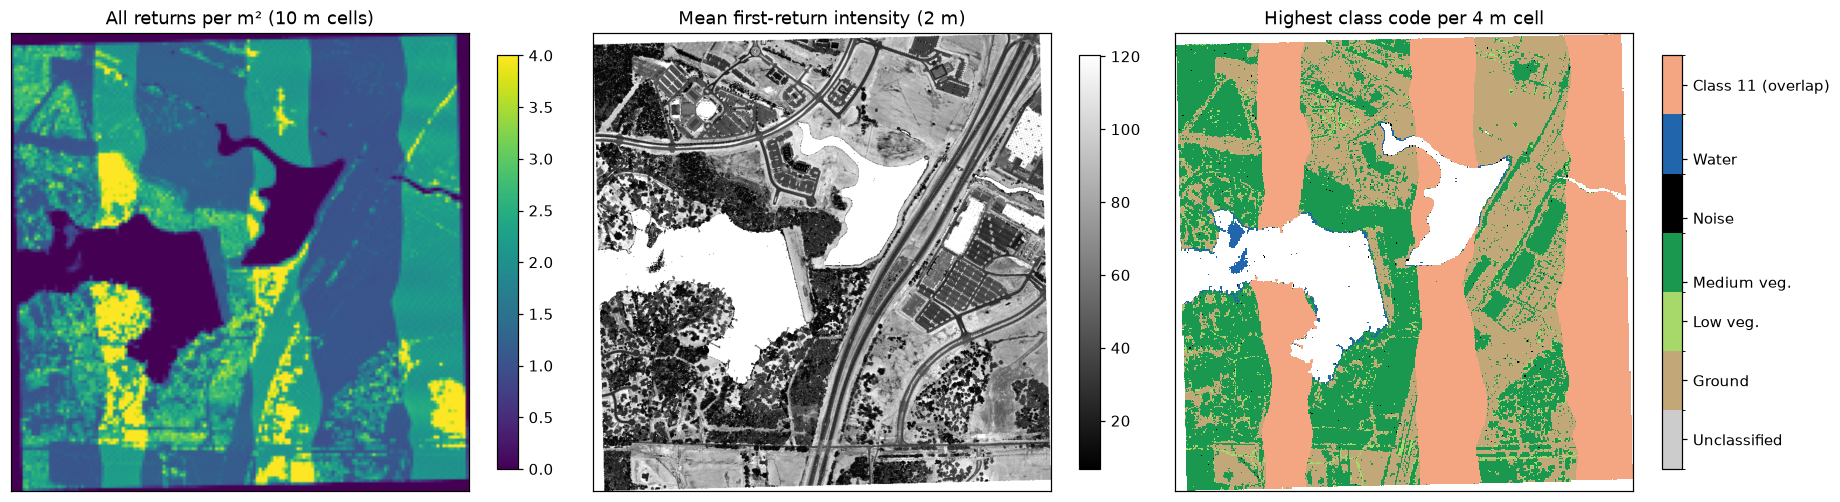

median density 1.46 points/m², 1.12 pulses/m²


In [13]:
density = rs.lidar.rasterize(pc, 10.0, stat="count") / 100.0  # all returns per m² in 10 m cells
pulses = rs.lidar.rasterize(pc.first_returns(), 10.0, stat="count") / 100.0  # first returns = pulses per m²
intensity = rs.lidar.rasterize(pc.first_returns(), 2.0, value="intensity", stat="mean")  # mean intensity, 2 m
top_class = rs.lidar.rasterize(pc, 4.0, value="classification", stat="max")  # highest class code per 4 m cell

fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # three panels
rs.viz.plot_raster(density, ax=axes[0], cmap="viridis", vmax=4, title="All returns per m² (10 m cells)")  # density
rs.viz.plot_raster(intensity, ax=axes[1], cmap="gray", robust=True, title="Mean first-return intensity (2 m)")  # intensity
rs.viz.plot_raster(top_class, ax=axes[2], title="Highest class code per 4 m cell",  # classes
                   categorical={1: ("Unclassified", "#cccccc"), 2: ("Ground", "#c2a878"), 3: ("Low veg.", "#a6d96a"),
                                4: ("Medium veg.", "#1a9850"), 7: ("Noise", "#000000"), 9: ("Water", "#2166ac"),
                                11: ("Class 11 (overlap)", "#f4a582")})
for a in axes: a.set_xticks([]); a.set_yticks([])  # no tick labels
plt.tight_layout(); plt.show()  # draw
print(f"median density {float(density.median()):.2f} points/m², {float(pulses.median()):.2f} pulses/m²")  # summary

Density is higher where flight lines overlap (the stripes) and drops over water, which absorbs the near-infrared laser. Intensity looks like a near-infrared photograph: grass and crowns are bright, asphalt and water dark.

**Return structure by class.** The share of points that are first, intermediate, last or single returns differs strongly between ground and vegetation, which is the basis of many classification rules.


In [14]:
rtype = np.select([pc["number_of_returns"] == 1, pc["return_number"] == 1,  # single, first of many,
                   pc["return_number"] == pc["number_of_returns"]],  # last of many,
                  ["single", "first of many", "last of many"], "intermediate")  # else intermediate
tab = pd.crosstab(pd.Series(pc["classification"]).map(lambda k: ASPRS_CLASSES.get(int(k), k)), rtype,  # class x type
                  normalize="index", rownames=["class"], colnames=["return type"])
tab[["single", "first of many", "intermediate", "last of many"]].round(3)  # share of each type per class

return type,single,first of many,intermediate,last of many
class,,,,
ground,0.777,0.000,0.000,0.223
low_noise,0.639,0.000,0.000,0.361
low_vegetation,0.033,0.967,0.000,0.000
medium_vegetation,0.358,0.000,0.435,0.208
road,0.644,0.141,0.070,0.146
unclassified,0.745,0.000,0.000,0.255
water,0.902,0.000,0.000,0.098


Ground points are mostly single returns or the last return of a pulse, as expected. The two vegetation classes reveal how this producer worked: "low vegetation" is almost entirely the **first** return of multi-return pulses and "medium vegetation" the later returns, so in this dataset the vegetation codes describe the position of a return in its pulse rather than a height band. Height above ground, computed in the processing notebook, is the reliable way to separate low from tall vegetation here.


## Cross-sections and 3D views

A thin slice through the cloud shows the vertical structure that LiDAR captures. `rs.lidar.cross_section` keeps the points within half a width of a line and adds their distance along it; `rs.lidar.plot_cross_section` draws them coloured by any field.


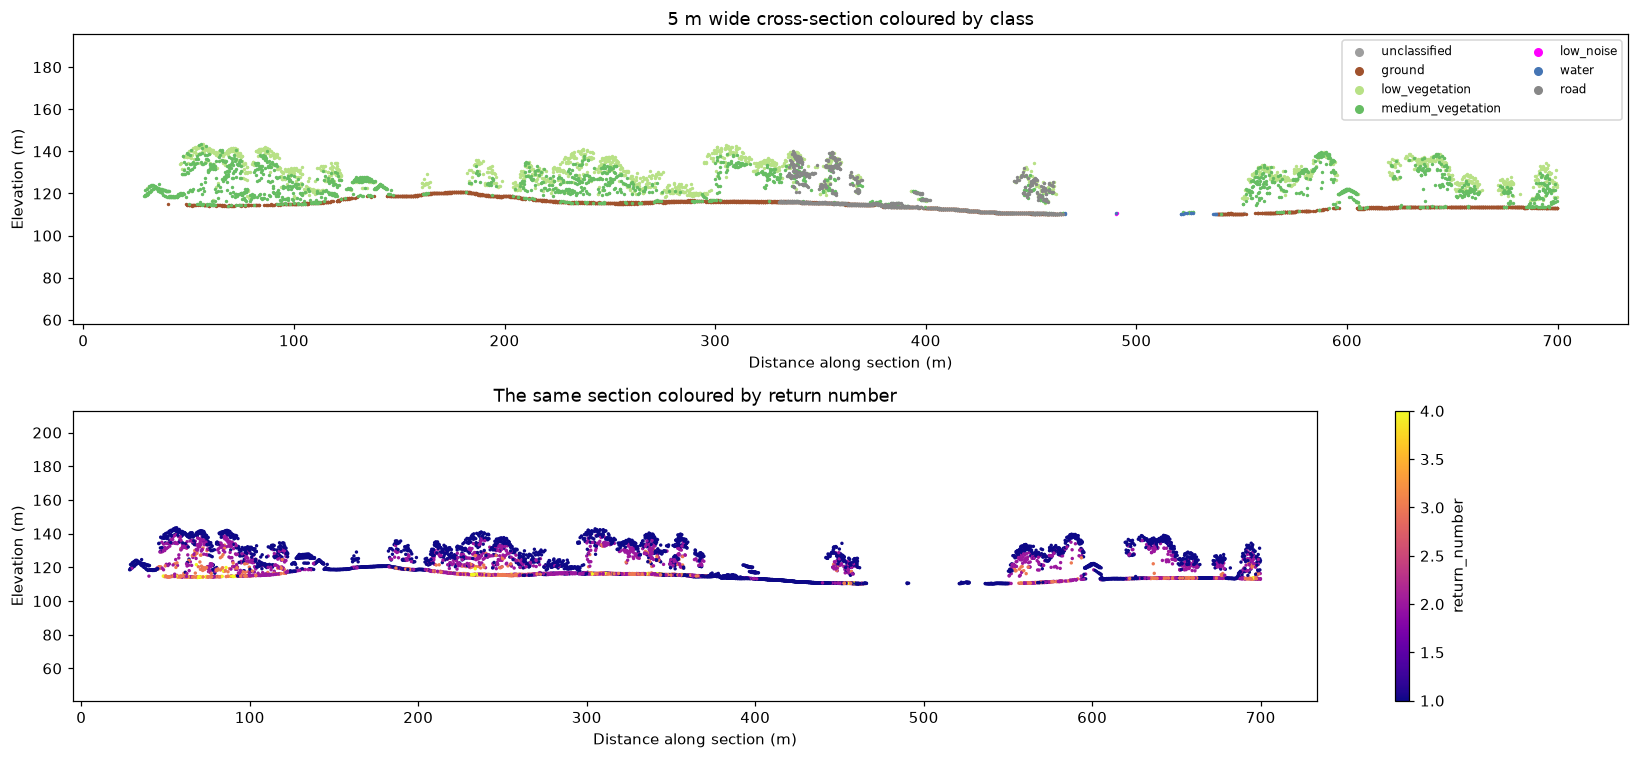

In [15]:
cy = ymin + 0.25 * (ymax - ymin)  # a west-east line a quarter of the way up the tile
sec = rs.lidar.cross_section(pc, (xmin, cy), (xmin + 700, cy), width=5.0)  # 700 m long, 5 m wide slice
fig, axes = plt.subplots(2, 1, figsize=(15, 7))  # two panels
rs.lidar.plot_cross_section(sec, color_by="classification", ax=axes[0], s=1.5,  # by class
                            title="5 m wide cross-section coloured by class")
rs.lidar.plot_cross_section(sec, color_by="return_number", ax=axes[1], s=1.5, cmap="plasma",  # by return number
                            title="The same section coloured by return number")
plt.tight_layout(); plt.show()  # draw

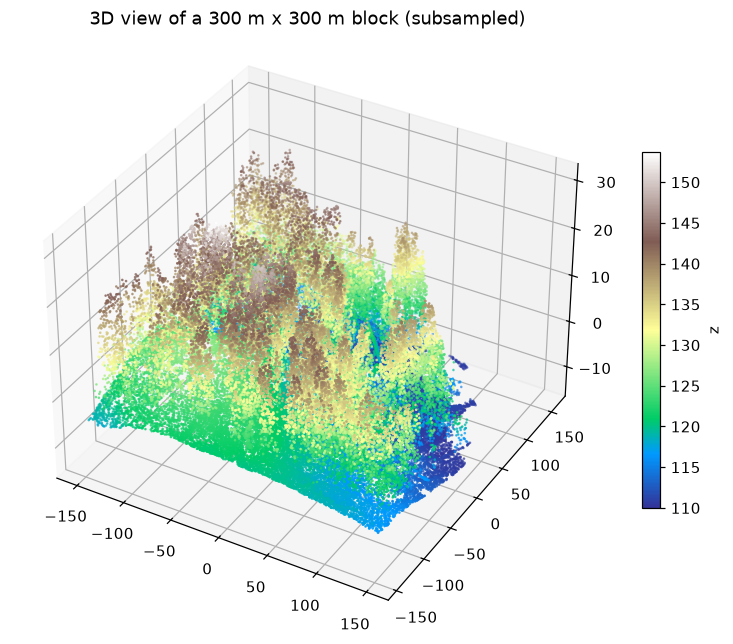

In [16]:
sub = pc.crop(xmin + 200, ymin + 200, xmin + 500, ymin + 500)  # a 300 m x 300 m block
ax = rs.viz.plot_pointcloud(sub, color_by="z", max_points=80_000, backend="matplotlib", cmap="terrain")  # 3D scatter
ax.set_title("3D view of a 300 m x 300 m block (subsampled)"); ax.view_init(35, -60); plt.show()  # title, angle, draw

`plot_pointcloud` subsamples to `max_points` so matplotlib stays responsive. With `pyvista` or `Open3D` installed, `backend="pyvista"` opens an interactive window instead.

The UB campus looks very different: buildings, parking lots, a stadium and lawns. The intensity image makes roofs, asphalt, running track and grass distinct, and the 3D view shows the buildings standing above the ground.


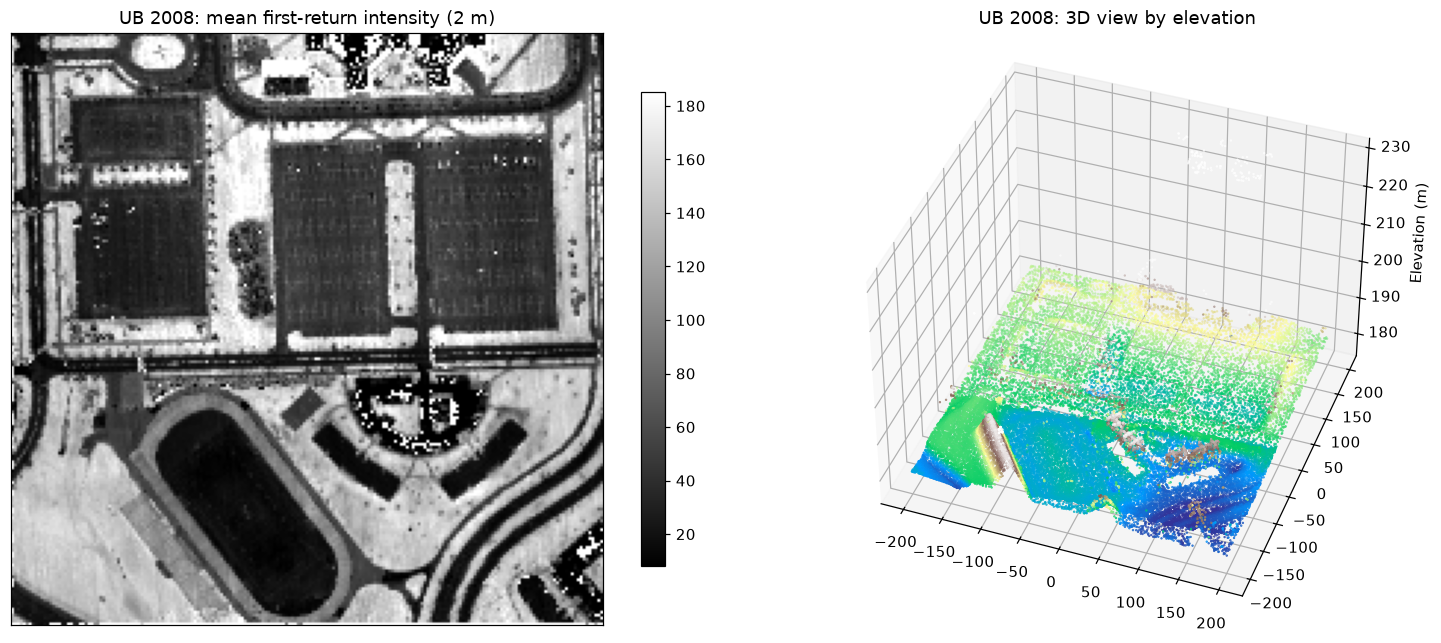

In [17]:
ux, uy = np.mean(ub.bbox[::2]), np.mean(ub.bbox[1::2])  # centre of the UB tile
ub_block = ub.crop(ux - 200, uy - 200, ux + 200, uy + 200)  # a 400 m block of the campus
fig = plt.figure(figsize=(14, 6))  # two panels
ax1 = fig.add_subplot(1, 2, 1)  # plan view
ub_int = rs.lidar.rasterize(ub_block.first_returns(), 2.0, value="intensity", stat="mean")  # 2 m intensity image
rs.viz.plot_raster(ub_int, ax=ax1, cmap="gray", title="UB 2008: mean first-return intensity (2 m)")  # plan view
ax1.set_xticks([]); ax1.set_yticks([])  # no ticks
ax2 = fig.add_subplot(1, 2, 2, projection="3d")  # 3D view
s = ub_block.filter(np.random.default_rng(0).random(len(ub_block)) < 0.15)  # 15 % of the points
ax2.scatter(s.x - ux, s.y - uy, s.z, c=s.z, cmap="terrain", s=0.3, vmin=np.percentile(s.z, 1),  # by elevation
            vmax=np.percentile(s.z, 99.5))
ax2.set(zlabel="Elevation (m)", title="UB 2008: 3D view by elevation"); ax2.view_init(40, -70)  # labels and angle
plt.tight_layout(); plt.show()  # draw

## Cloud-native access: reading a window from COPC

A COPC file stores its points in an octree: the root node holds a sparse sample of the whole area and every level below adds detail in smaller cubes. A reader can therefore fetch only the nodes that cover a region, or stop at a coarse level for an overview. Over the web this works with HTTP range requests, so only the requested bytes are downloaded. `rs.lidar.read_las` passes `bounds` (in the file's CRS) and `resolution` to laspy's COPC reader; the same call works for a local path or a URL.


In [18]:
import laspy  # LAS/LAZ/COPC library used by read_las
with laspy.CopcReader.open(MADISON) as r:  # read only the header and the octree hierarchy
    hdr = r.header  # the header
    print(f"{hdr.point_count:,} points | bounds {np.round(hdr.mins[:2])} to {np.round(hdr.maxs[:2])} (ft)")  # extent
mid = (hdr.mins[:2] + hdr.maxs[:2]) / 2  # centre of the file
win = (mid[0] - 1000, mid[1] - 1000, mid[0] + 1000, mid[1] + 1000)  # a 2,000 ft (610 m) window

rows, parts = [], {}  # timing rows and the clouds read
for res in (None, 4.0, 16.0, 64.0):  # full resolution, then coarser levels of detail (ft)
    t0 = time.perf_counter()  # start the timer
    parts[res] = rs.lidar.read_las(MADISON, bounds=win, resolution=res)  # read only that window and level
    rows.append({"resolution (ft)": res or "full", "points": len(parts[res]),  # points read
                 "seconds": round(time.perf_counter() - t0, 2)})  # time taken
pd.DataFrame(rows)  # show the table

4,068,294 points | bounds [2353000. 1075500.] to [2358000. 1080500.] (ft)


,resolution (ft),points,seconds
0,full,488770,0.09
1,4.0,488770,0.10
2,16.0,192429,0.06
3,64.0,4571,0.02


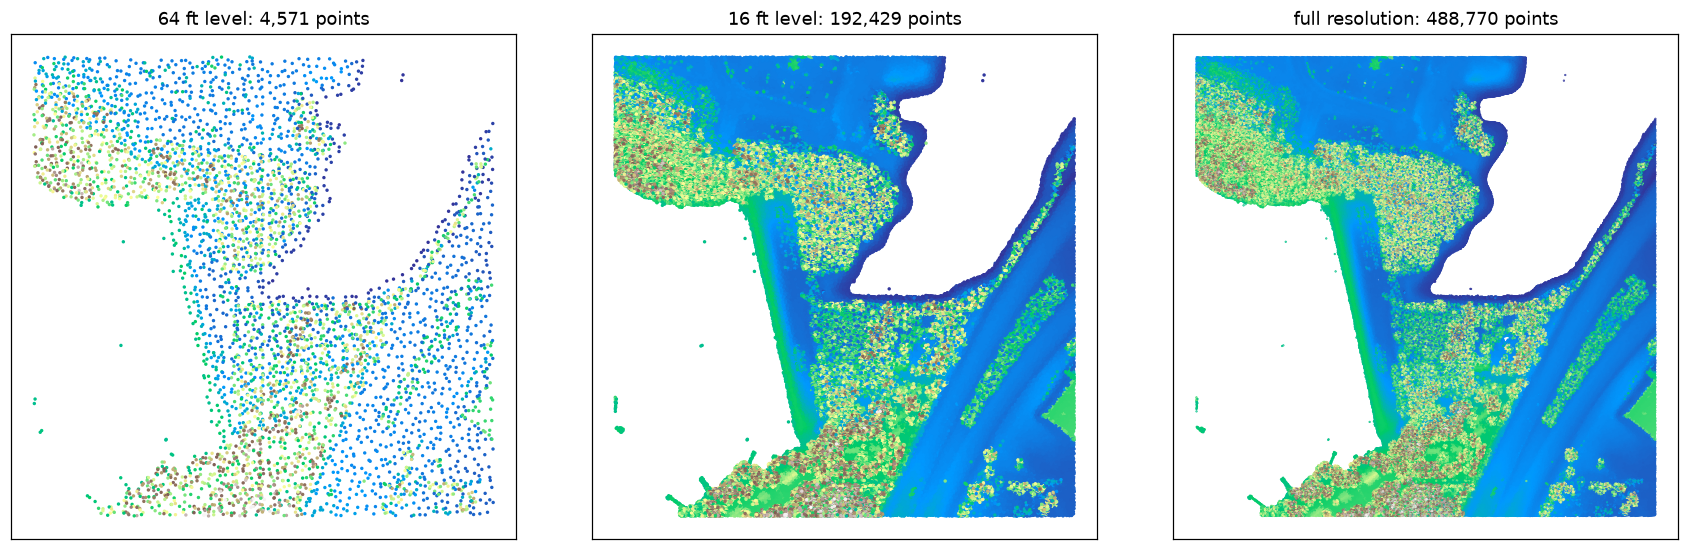

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))  # three panels
for ax, res in zip(axes, (64.0, 16.0, None)):  # coarse to full
    p = parts[res]  # the cloud read at this level
    ax.scatter(p.x, p.y, c=p.z, s=0.2 if res is None else 1.5, cmap="terrain")  # plan view by elevation
    ax.set(title=f"{'full resolution' if res is None else f'{res:g} ft level'}: {len(p):,} points",  # title
           xticks=[], yticks=[], aspect="equal")  # no ticks
plt.tight_layout(); plt.show()  # draw

## Writing point clouds and finding public LiDAR

`rs.lidar.write_las` writes LAS or compressed LAZ (by the file extension) with the CRS in the header; `rs.lidar.write_ply` writes PLY for CloudCompare, MeshLab or Open3D. The cell writes the metric Madison cloud, which the following notebooks read, and a small tile in both formats, and checks the round trip.


In [20]:
rs.lidar.write_las(pc, DATA / "madison_utm.laz")  # the whole metric cloud, used by later notebooks
tile = pc.crop(xmin, ymin, xmin + 300, ymin + 300)  # a 300 m tile
rs.lidar.write_las(tile, DATA / "madison_tile_utm.laz")  # as LAZ
rs.lidar.write_ply(tile, OUT / "madison_tile_utm.ply")  # as binary PLY
back = rs.lidar.read_las(DATA / "madison_tile_utm.laz")  # read the LAZ back
# summary line
print(f"tile: {len(tile):,} points | LAZ {os.path.getsize(DATA / 'madison_tile_utm.laz') / 1e6:.1f} MB | "
      f"PLY {os.path.getsize(OUT / 'madison_tile_utm.ply') / 1e6:.1f} MB")  # sizes
print(f"read back {len(back):,} points, CRS EPSG:{back.crs}, max |Δz| = {np.abs(back.z - tile.z).max():.4f} m")  # check

tile: 127,381 points | LAZ 0.8 MB | PLY 7.1 MB
read back 127,381 points, CRS EPSG:32615, max |Δz| = 0.0005 m


The largest height difference after the round trip is half a millimetre: LAS stores integers with a scale of 0.001 m, so coordinates are rounded to the nearest millimetre.

**Finding public LiDAR.** `rs.lidar.usgs_3dep_ept` looks up the USGS 3DEP Entwine Point Tile datasets that cover a longitude/latitude box. For Ithaca it finds the 2020 Finger Lakes project, the source of the tiles in `Data/08_remote_sensing/08_06_lidar/Ithaca`. Each EPT dataset is described by an `ept.json` file; `rs.lidar.read_pdal` streams points from it when the PDAL Python bindings are installed (a conda package).


In [21]:
from geolattice.network import is_online  # internet check
if is_online("https://raw.githubusercontent.com"):  # only with an internet connection
    import requests  # HTTP requests
    eps = rs.lidar.usgs_3dep_ept((-76.52, 42.42, -76.48, 42.45))  # 3DEP datasets covering Ithaca
    print(eps)  # their EPT URLs
    meta = requests.get(eps[0], timeout=60).json()  # the EPT description of the first one
    print(f"{eps[0].split('/')[-2]}: {meta['points']:,} points | span {meta['span']} | "  # summary line
          f"dimensions {[d['name'] for d in meta['schema']][:8]} ...")  # size and fields of the archive
else:  # offline
    print("Offline: skipping the 3DEP lookup.")  # summary line

['https://s3-us-west-2.amazonaws.com/usgs-lidar-public/NY_FingerLakes_1_2020/ept.json']


NY_FingerLakes_1_2020: 25,243,762,789 points | span 128 | dimensions ['X', 'Y', 'Z', 'Intensity', 'ReturnNumber', 'NumberOfReturns', 'ScanDirectionFlag', 'EdgeOfFlightLine'] ...


## Summary and exercises

**Key points**

- LiDAR measures range from the round-trip time of laser pulses, $R = c\Delta t / 2$, and georeferences each echo with GNSS, an IMU and the scan angle.
- Footprint, pulse rate, flying height, speed and scan angle set the point density; national specifications (3DEP QL0 to QL3) set minimum densities and accuracies.
- One pulse can return several echoes; first returns describe the canopy top and roofs, last returns often reach the ground. Full-waveform and single-photon systems record more of the returned signal.
- LAS stores points with a header, CRS records and per-point attributes; LAZ compresses it about ten times; COPC and EPT make large archives streamable by region and level of detail; LASX files are only ArcGIS indexes.
- Always check units and coordinate reference systems: feet versus metres, degrees versus metres, and orthometric versus ellipsoidal heights.
- Class codes, return structure, density and intensity summarise what a dataset contains; producers do not always use class codes as the ASPRS table says.

**`geolattice.rsense` functions used:** `rs.lidar.las_info`, `rs.lidar.read_las` (including COPC `bounds` and `resolution`), `rs.lidar.reproject`, `rs.core.utm_epsg`, `rs.lidar.summary`, `rs.lidar.rasterize`, `rs.lidar.cross_section`, `rs.lidar.plot_cross_section`, `rs.lidar.plot_classification`, `rs.viz.plot_pointcloud`, `rs.viz.plot_raster`, `rs.lidar.write_las`, `rs.lidar.write_ply`, `rs.lidar.usgs_3dep_ept`, and the `PointCloud` methods `crop`, `filter`, `first_returns` and `with_field`.

**Exercises**

1. Plan a drone survey at 80 m with a 240 kHz sensor, 70° scan angle and 8 m/s ground speed. What density does it reach, and how many flight lines cover a 500 m wide field?
2. Repeat the waveform simulation for an open grass spot and for a building roof. How do RH50 and RH98 change?
3. Map the share of multi-return pulses per 10 m cell for Madison. Where is it highest?
4. Reproject a UB tile to UTM 17N with `rs.lidar.reproject` and compare its area with the area you get by multiplying the degree extents by 111 km. Why do they differ?
5. Read a 500 m window of an Ithaca tile at full density and with `voxel_downsample(1.0)`. How many points does each keep, and what disappears in a cross-section?
